# 01 · Market Risk & Regime Lab — NIFTY 50

**Question:** How risky is the Indian large-cap market *really*, and which risk model would a
risk desk trust?

Most student projects report one volatility number and stop. Here we:
1. Test whether returns are normal (they are not) and quantify the fat tails.
2. Fit a **GARCH(1,1) with Student-t innovations** to model volatility clustering.
3. Forecast 1-day **99% Value-at-Risk** five different ways and **backtest** each with the
   Kupiec (coverage) and Christoffersen (independence) tests — the same tests regulators use.
4. Map the worst drawdowns and recovery times.
5. Ask whether **valuation (index P/E) predicts the next 3 years of returns**.

Data: NIFTY 50 price index, Feb-2012 → Sep-2026 (NSE EOD).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if (Path.cwd().parent / "src").exists() else "src")

import numpy as np
import pandas as pd
from arch import arch_model
from scipy import stats

from nql import data, metrics
from nql.plotting import PALETTE, plt, save

px = data.load_frame("nifty 50")
close = px["Close"].astype(float)
pe = pd.to_numeric(px["P/E"], errors="coerce")
r = close.pct_change().dropna()
lr = np.log(close).diff().dropna()
print(f"{len(r):,} trading days, {r.index[0].date()} → {r.index[-1].date()}")

3,600 trading days, 2012-02-22 → 2026-09-25


## 1 · Are NIFTY returns normal?

In [2]:
sk, ku = stats.skew(lr), stats.kurtosis(lr)  # excess kurtosis
jb = stats.jarque_bera(lr)
sigma = lr.std()
obs_4sd = int((lr.abs() > 4 * sigma).sum())
exp_4sd = len(lr) * 2 * stats.norm.sf(4)
dist = {
    "ann_return_cagr": metrics.cagr(r), "ann_vol": metrics.ann_vol(r),
    "skew": sk, "excess_kurtosis": ku, "jarque_bera_p": jb.pvalue,
    "moves_beyond_4sd_observed": obs_4sd, "moves_beyond_4sd_expected_if_normal": exp_4sd,
    "worst_day": float(r.min()), "worst_day_date": str(r.idxmin().date()),
    "best_day": float(r.max()), "best_day_date": str(r.idxmax().date()),
}
pd.Series(dist)

ann_return_cagr                          0.104318
ann_vol                                  0.160315
skew                                    -1.091929
excess_kurtosis                         16.675416
jarque_bera_p                                 0.0
moves_beyond_4sd_observed                      18
moves_beyond_4sd_expected_if_normal      0.228033
worst_day                               -0.129805
worst_day_date                         2020-03-23
best_day                                 0.087632
best_day_date                          2020-04-07
dtype: object

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


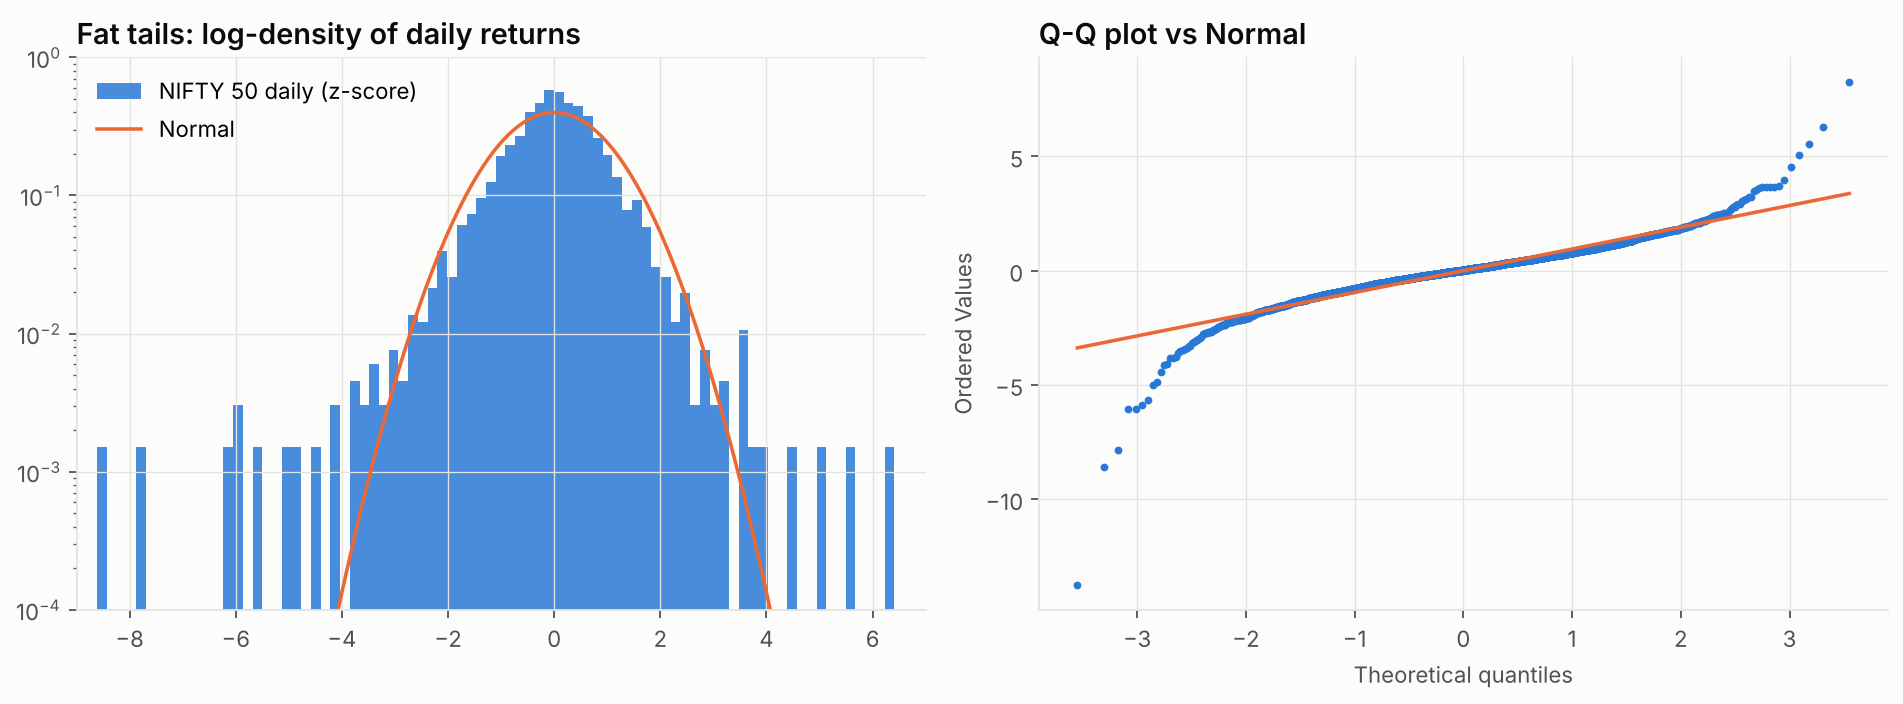

PosixPath('/home/claude/nse-quant-lab/reports/figures/01_fat_tails.png')

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
z = (lr - lr.mean()) / sigma
axes[0].hist(z, bins=120, density=True, color=PALETTE[0], alpha=0.85, label="NIFTY 50 daily (z-score)")
xs = np.linspace(-8, 8, 400)
axes[0].plot(xs, stats.norm.pdf(xs), color=PALETTE[1], label="Normal")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-4, 1); axes[0].set_xlim(-9, 7)
axes[0].set_title("Fat tails: log-density of daily returns"); axes[0].legend()
stats.probplot(z, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=PALETTE[0], markersize=2.5)
axes[1].get_lines()[1].set(color=PALETTE[1])
axes[1].set_title("Q-Q plot vs Normal")
save(fig, "01_fat_tails")

Excess kurtosis far above 0 and a Jarque-Bera p-value of ~0 reject normality. A ±4σ day
"should" happen roughly once in 60 years under a normal model; NIFTY has had many more. Any risk
model that assumes normality will under-state tail risk — which motivates the next sections.

## 2 · Volatility clustering — GARCH(1,1) with Student-t errors

In [4]:
am = arch_model(lr * 100, vol="GARCH", p=1, q=1, dist="t", mean="Constant")
g = am.fit(disp="off")
omega, alpha, beta, nu = g.params[["omega", "alpha[1]", "beta[1]", "nu"]]
persistence = alpha + beta
half_life = np.log(0.5) / np.log(persistence)
long_run_vol = np.sqrt(omega / (1 - persistence) * 252) / 100
cond_vol = g.conditional_volatility / 100 * np.sqrt(252)
garch = {"omega": omega, "alpha": alpha, "beta": beta, "nu": nu, "persistence": persistence,
         "half_life_days": half_life, "long_run_vol": long_run_vol,
         "current_cond_vol": float(cond_vol.iloc[-1]), "peak_cond_vol": float(cond_vol.max()),
         "peak_cond_vol_date": str(cond_vol.idxmax().date())}
print(g.summary().tables[1]); pd.Series(garch)

                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0665  1.304e-02      5.105  3.316e-07 [4.099e-02,9.209e-02]


omega                   0.022123
alpha                   0.070626
beta                    0.903911
nu                      6.633427
persistence             0.974537
half_life_days         26.873693
long_run_vol            0.147969
current_cond_vol        0.124311
peak_cond_vol           0.804192
peak_cond_vol_date    2020-03-24
dtype: object

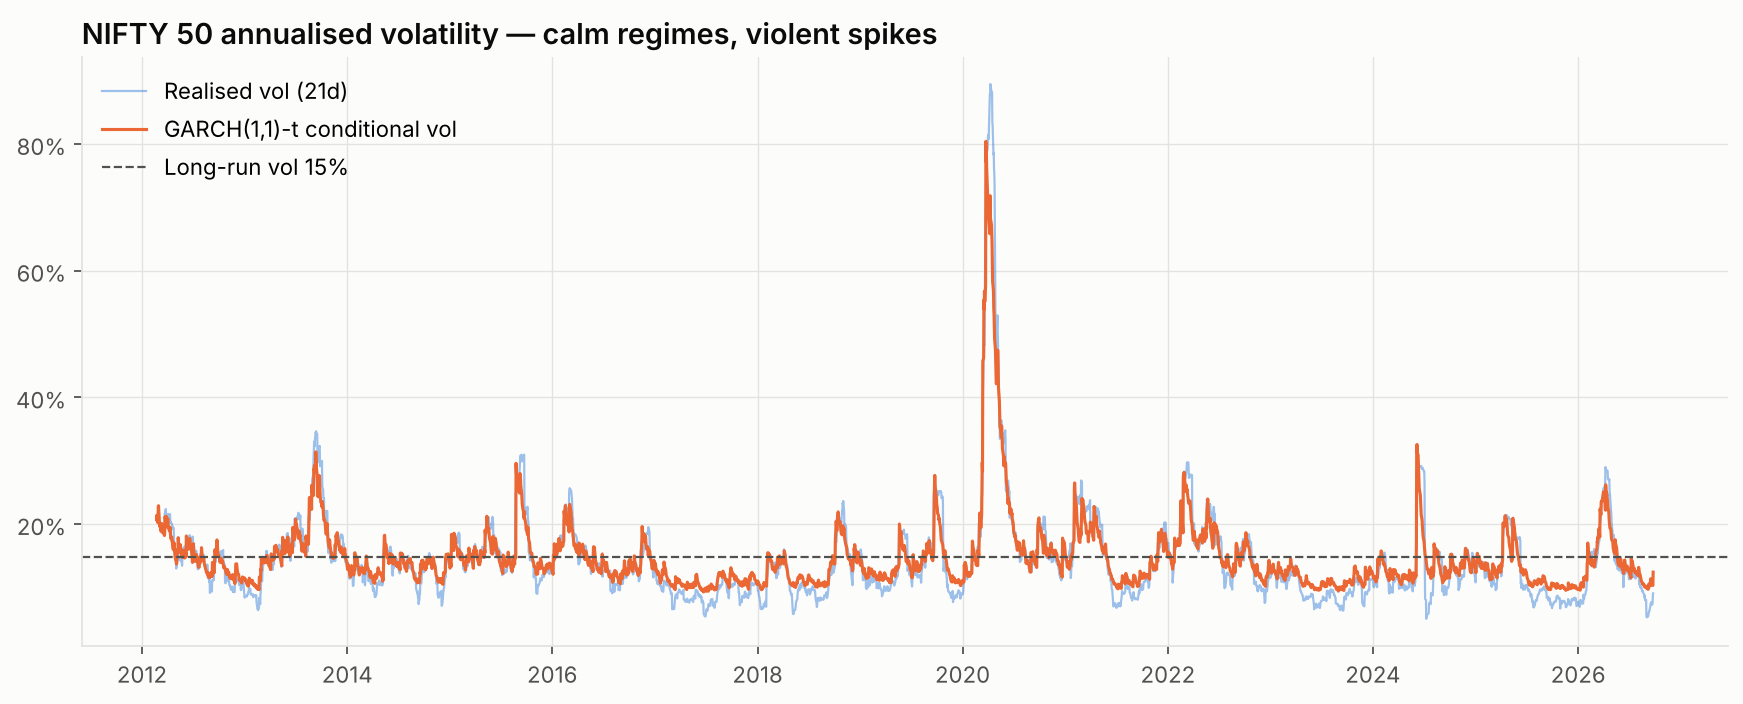

PosixPath('/home/claude/nse-quant-lab/reports/figures/01_garch_vol.png')

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
realised = lr.rolling(21).std() * np.sqrt(252)
ax.plot(realised.index, realised, color=PALETTE[0], alpha=0.45, lw=1, label="Realised vol (21d)")
ax.plot(cond_vol.index, cond_vol, color=PALETTE[1], lw=1.4, label="GARCH(1,1)-t conditional vol")
ax.axhline(long_run_vol, color="#52514e", ls="--", lw=1, label=f"Long-run vol {long_run_vol:.0%}")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("NIFTY 50 annualised volatility — calm regimes, violent spikes"); ax.legend(loc="upper left")
save(fig, "01_garch_vol")

Persistence (α+β) close to 1 means volatility shocks decay slowly: the half-life tells you how many
trading days it takes for half of a shock to fade. This is why "vol targeting" (module 02) works.

### 2b · The leverage effect — GJR-GARCH with skewed-t errors
Plain GARCH treats a +3% day and a −3% day identically. Markets don't: falls raise volatility far
more than rallies. GJR-GARCH adds a term γ that switches on only for negative shocks, and the
skewed-t distribution (Hansen, 1994) lets the left tail be heavier than the right.

In [6]:
gjr = arch_model(lr * 100, vol="GARCH", p=1, o=1, q=1, dist="skewt").fit(disp="off")
lev = {"alpha": gjr.params["alpha[1]"], "gamma": gjr.params["gamma[1]"], "beta": gjr.params["beta[1]"],
       "skew_lambda": gjr.params["lambda"], "nu": gjr.params["eta"],
       "aic_garch_t": g.aic, "aic_gjr_skewt": gjr.aic, "bic_garch_t": g.bic, "bic_gjr_skewt": gjr.bic}
garch["leverage_model"] = lev
pd.Series(lev)

alpha            1.222321e-13
gamma            1.339040e-01
beta             8.990797e-01
skew_lambda     -1.159531e-01
nu               7.268055e+00
aic_garch_t      9.158155e+03
aic_gjr_skewt    9.055692e+03
bic_garch_t      9.189098e+03
bic_gjr_skewt    9.099013e+03
dtype: float64

γ is large and α is ~0: on NIFTY, **only bad news moves volatility**. Both AIC and BIC prefer the
GJR-skew-t model, and it becomes our fifth VaR model below.

## 3 · Value-at-Risk: five models, one honest backtest

Each day we forecast tomorrow's 99% 1-day VaR using **only information available today**
(rolling 500-day window, GARCH refit every 21 days on an expanding window). Then we count how
often the actual loss breached the forecast. A correct 99% model should be breached ~1% of days.

* **Historical simulation** — empirical 1st percentile of the last 500 days.
* **Parametric Normal** — μ − 2.33σ.
* **Cornish-Fisher** — Normal quantile corrected for skew and kurtosis.
* **GARCH-t (filtered)** — GARCH volatility forecast × Student-t quantile.
* **GJR-GARCH skew-t** — asymmetric volatility × skewed-t quantile.

In [7]:
ALPHA = 0.01
W = 500
lrv = lr.values
idx = lr.index
var = {k: pd.Series(np.nan, index=idx) for k in ["Historical", "Normal", "Cornish-Fisher"]}
zq = stats.norm.ppf(ALPHA)
for t in range(W, len(lr)):
    win = lrv[t - W:t]
    mu, sd = win.mean(), win.std(ddof=1)
    s, k = stats.skew(win), stats.kurtosis(win)
    zcf = zq + (zq**2 - 1) * s / 6 + (zq**3 - 3 * zq) * k / 24 - (2 * zq**3 - 5 * zq) * s**2 / 36
    var["Historical"].iloc[t] = np.quantile(win, ALPHA)
    var["Normal"].iloc[t] = mu + zq * sd
    var["Cornish-Fisher"].iloc[t] = mu + zcf * sd

# GARCH family: refit every 21 days on an expanding window; in between, roll the variance
# recursion forward one day at a time with the frozen parameters (strictly out-of-sample).
def garch_var(o: int, dist: str, refit_every: int = 21) -> pd.Series:
    out = pd.Series(np.nan, index=idx)
    for t in range(W, len(lr)):
        if (t - W) % refit_every == 0:
            res = arch_model(lr.iloc[:t] * 100, vol="GARCH", p=1, o=o, q=1, dist=dist).fit(disp="off")
            prm = res.params
            shape = prm[[c for c in prm.index if c in ("nu", "eta", "lambda")]].values
            q = res.model.distribution.ppf(ALPHA, shape)
            h = res.forecast(horizon=1, reindex=False).variance.values[-1, 0]
        else:
            eps = lrv[t - 1] * 100 - prm["mu"]
            h = prm["omega"] + (prm["alpha[1]"] + (prm.get("gamma[1]", 0) if eps < 0 else 0)) * eps**2 + prm["beta[1]"] * h
        out.iloc[t] = (prm["mu"] + np.sqrt(h) * q) / 100
    return out


var["GARCH-t"] = garch_var(0, "t")
var["GJR-GARCH skew-t"] = garch_var(1, "skewt")

In [8]:
def kupiec(hits: np.ndarray, p: float) -> float:
    n, x = len(hits), hits.sum()
    if x == 0:
        return 1.0
    lr_uc = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - x / n) - x * np.log(x / n))
    return float(stats.chi2.sf(lr_uc, 1))


def christoffersen(hits: np.ndarray) -> float:
    h0, h1 = hits[:-1], hits[1:]
    n00 = ((h0 == 0) & (h1 == 0)).sum(); n01 = ((h0 == 0) & (h1 == 1)).sum()
    n10 = ((h0 == 1) & (h1 == 0)).sum(); n11 = ((h0 == 1) & (h1 == 1)).sum()
    p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1); p = (n01 + n11) / (n00 + n01 + n10 + n11)
    def ll(a, b, q):
        return (a * np.log(1 - q) if a and q < 1 else 0) + (b * np.log(q) if b and q > 0 else 0)
    lr_ind = -2 * (ll(n00 + n10, n01 + n11, p) - ll(n00, n01, p01) - ll(n10, n11, p11))
    return float(stats.chi2.sf(lr_ind, 1))


rows = []
for name, v in var.items():
    m = v.notna()
    hits = (lr[m] < v[m]).astype(int).values
    es_model = lr[m][lr[m] < v[m]].mean()
    rows.append({"model": name, "days": int(m.sum()), "breaches": int(hits.sum()),
                 "expected": round(m.sum() * ALPHA, 1), "breach_rate": hits.mean(),
                 "kupiec_p": kupiec(hits, ALPHA), "christoffersen_p": christoffersen(hits),
                 "avg_loss_when_breached": float(es_model),
                 "verdict": "PASS" if kupiec(hits, ALPHA) > 0.05 and christoffersen(hits) > 0.05 else "FAIL"})
var_bt = pd.DataFrame(rows).set_index("model")
var_bt

,days,breaches,expected,breach_rate,kupiec_p,christoffersen_p,avg_loss_when_breached,verdict
model,,,,,,,,
Historical,3100,38,31.0,0.012258,0.222294,0.001002,-0.035644,FAIL
Normal,3100,54,31.0,0.017419,0.000172,0.002383,-0.033062,FAIL
Cornish-Fisher,3100,18,31.0,0.005806,0.010880,0.003687,-0.043898,FAIL
GARCH-t,3100,47,31.0,0.015161,0.007280,0.744398,-0.032617,FAIL
GJR-GARCH skew-t,3100,32,31.0,0.010323,0.857496,0.413832,-0.035604,PASS


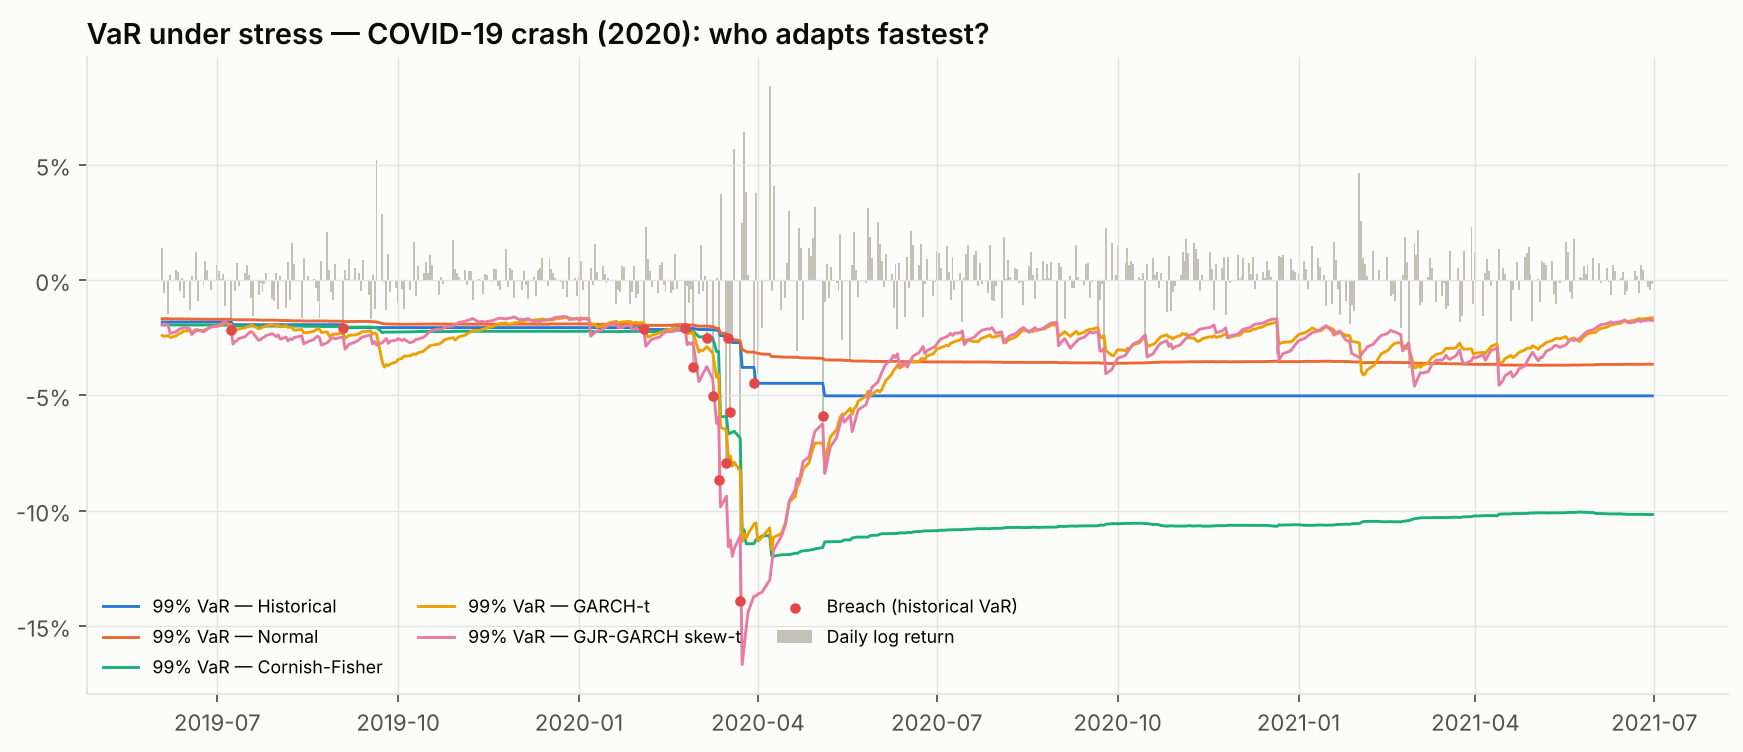

PosixPath('/home/claude/nse-quant-lab/reports/figures/01_var_covid.png')

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.8))
seg = slice("2019-06", "2021-06")
ax.bar(lr[seg].index, lr[seg], color="#c3c2b7", width=1.0, label="Daily log return")
for i, (name, v) in enumerate(var.items()):
    ax.plot(v[seg].index, v[seg], lw=1.3, color=PALETTE[i], label=f"99% VaR — {name}")
br = lr[seg][lr[seg] < var["Historical"][seg]]
ax.scatter(br.index, br, color=PALETTE[7], s=14, zorder=5, label="Breach (historical VaR)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("VaR under stress — COVID-19 crash (2020): who adapts fastest?"); ax.legend(ncol=3, fontsize=8, loc="lower left")
save(fig, "01_var_covid")

**Reading the backtest:** Kupiec tests whether the *number* of breaches matches 1%; Christoffersen
tests whether breaches *cluster* (a model that's breached five days in a row is useless when you
need it most). Normal VaR is typically breached too often — the fat tails from section 1 in action.
GARCH models react fastest in a crisis because they re-price volatility every day, and only the
asymmetric GJR-skew-t model captures both the *frequency* and the *clustering* of tail losses.

## 4 · Drawdowns and recovery

In [10]:
dd = metrics.drawdown(r)
episodes = []
in_dd, start = False, None
for d, v in dd.items():
    if not in_dd and v < 0:
        in_dd, start = True, d
    elif in_dd and v == 0:
        seg_ = dd[start:d]
        episodes.append({"peak": start, "trough": seg_.idxmin(), "recovered": d, "depth": seg_.min()})
        in_dd = False
if in_dd:
    seg_ = dd[start:]
    episodes.append({"peak": start, "trough": seg_.idxmin(), "recovered": pd.NaT, "depth": seg_.min()})
dd_tab = pd.DataFrame(episodes).sort_values("depth").head(6)
dd_tab["peak_to_trough_days"] = [(np.busday_count(a.date(), b.date())) for a, b in zip(dd_tab.peak, dd_tab.trough)]
dd_tab["recovery_days"] = [np.busday_count(b.date(), c.date()) if pd.notna(c) else None for b, c in zip(dd_tab.trough, dd_tab.recovered)]
dd_tab

,peak,trough,recovered,depth,peak_to_trough_days,recovery_days
76,2020-01-15,2020-03-23,2020-11-09,-0.384399,48,165.0
36,2015-03-04,2016-02-25,2017-03-14,-0.225166,256,273.0
101,2021-10-19,2022-06-17,2022-11-24,-0.172298,173,114.0
135,2024-09-27,2025-03-04,2026-01-02,-0.157667,112,218.0
136,2026-01-05,2026-03-30,NaT,-0.151818,60,NaN
10,2013-05-20,2013-08-28,2013-10-18,-0.145831,72,37.0


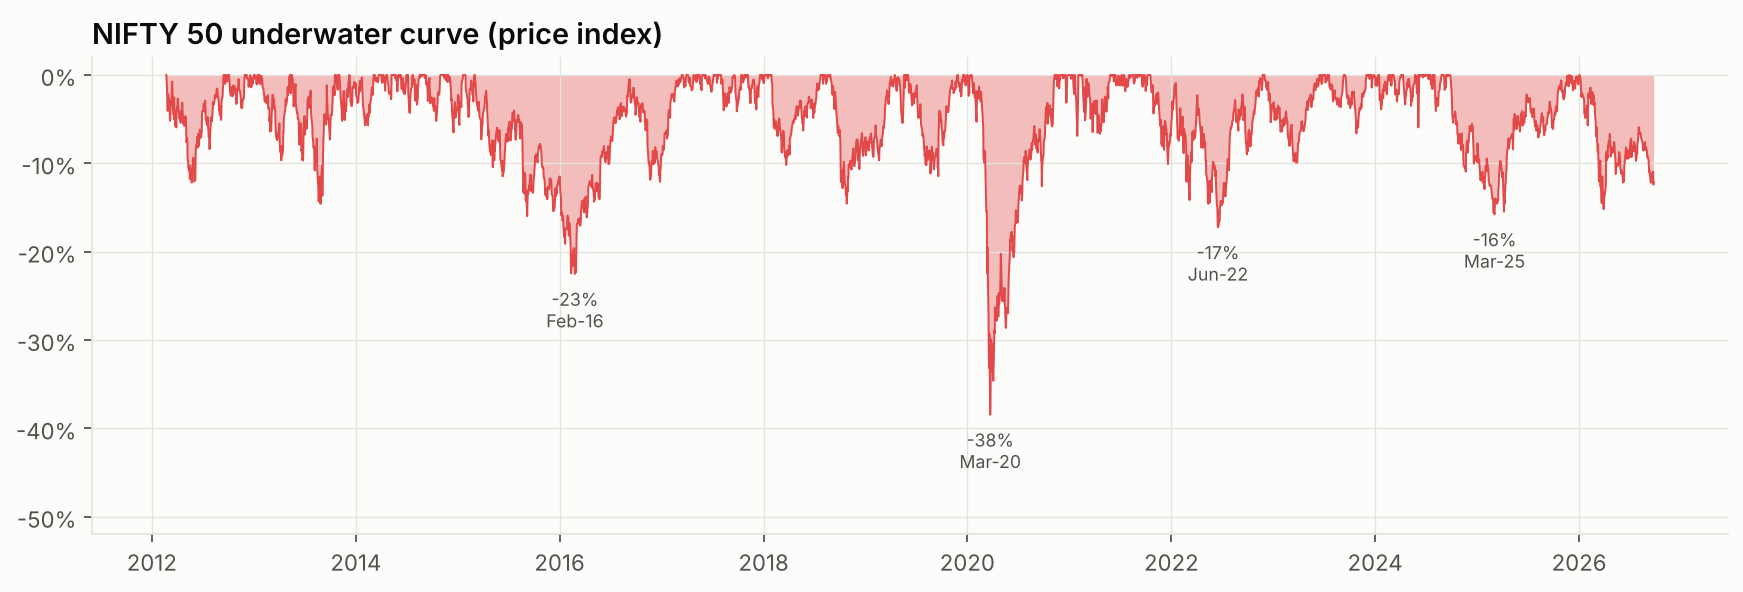

PosixPath('/home/claude/nse-quant-lab/reports/figures/01_drawdowns.png')

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(dd.index, dd, 0, color=PALETTE[7], alpha=0.35, lw=0)
ax.plot(dd.index, dd, color=PALETTE[7], lw=0.9)
for _, e in dd_tab.head(4).iterrows():
    ax.annotate(f"{e.depth:.0%}\n{e.trough:%b-%y}", (e.trough, e.depth), textcoords="offset points",
                xytext=(0, -24), ha="center", fontsize=8, color="#52514e")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(dd.min() * 1.35, 0.02)
ax.set_title("NIFTY 50 underwater curve (price index)")
save(fig, "01_drawdowns")

## 5 · Does valuation predict returns? NIFTY P/E vs next-3-year CAGR

NSE publishes the index P/E daily. Caveat: from **1-Apr-2021 NSE switched from standalone to
consolidated earnings**, which mechanically lowered the reported P/E by a few points — so we
z-score P/E *within* each regime before pooling, and test on non-overlapping-aware statistics.

In [12]:
H = 756  # 3 years of trading days
fwd = (close.shift(-H) / close) ** (252 / H) - 1
regime = pd.Series(np.where(pe.index < "2021-04-01", "standalone", "consolidated"), index=pe.index)
pe_z = pe.groupby(regime).transform(lambda s: (s - s.mean()) / s.std())
val = pd.concat({"pe": pe, "pe_z": pe_z, "fwd3y": fwd}, axis=1).dropna()
X = val["pe_z"]; Y = val["fwd3y"]
slope, intercept, rcorr, pval_naive, _ = stats.linregress(X, Y)
# Effective sample size with 756-day overlap is roughly n / H * 2 -> use Hansen-Hodrick-style rough
n_eff = len(val) / H * 2
t_adj = rcorr * np.sqrt((n_eff - 2) / (1 - rcorr**2))
val["bucket"] = pd.qcut(val["pe_z"], 5, labels=["Cheapest 20%", "Q2", "Q3", "Q4", "Richest 20%"])
bucket_tab = val.groupby("bucket", observed=True)["fwd3y"].agg(["mean", "median", "count"])
cur_pe = float(pe.dropna().iloc[-1])
cur_pct = float((pe[pe.index >= "2021-04-01"].dropna() <= cur_pe).mean())
valuation = {"corr_pe_z_vs_fwd3y": rcorr, "slope_per_1sd": slope, "t_stat_overlap_adjusted": t_adj,
             "current_pe": cur_pe, "current_pe_percentile_post2021": cur_pct,
             "bucket_mean_fwd3y": bucket_tab["mean"].to_dict()}
bucket_tab

,mean,median,count
bucket,,,
Cheapest 20%,0.135804,0.132032,569
Q2,0.125300,0.117963,569
Q3,0.091020,0.091633,569
Q4,0.123743,0.128321,571
Richest 20%,0.148669,0.148983,567


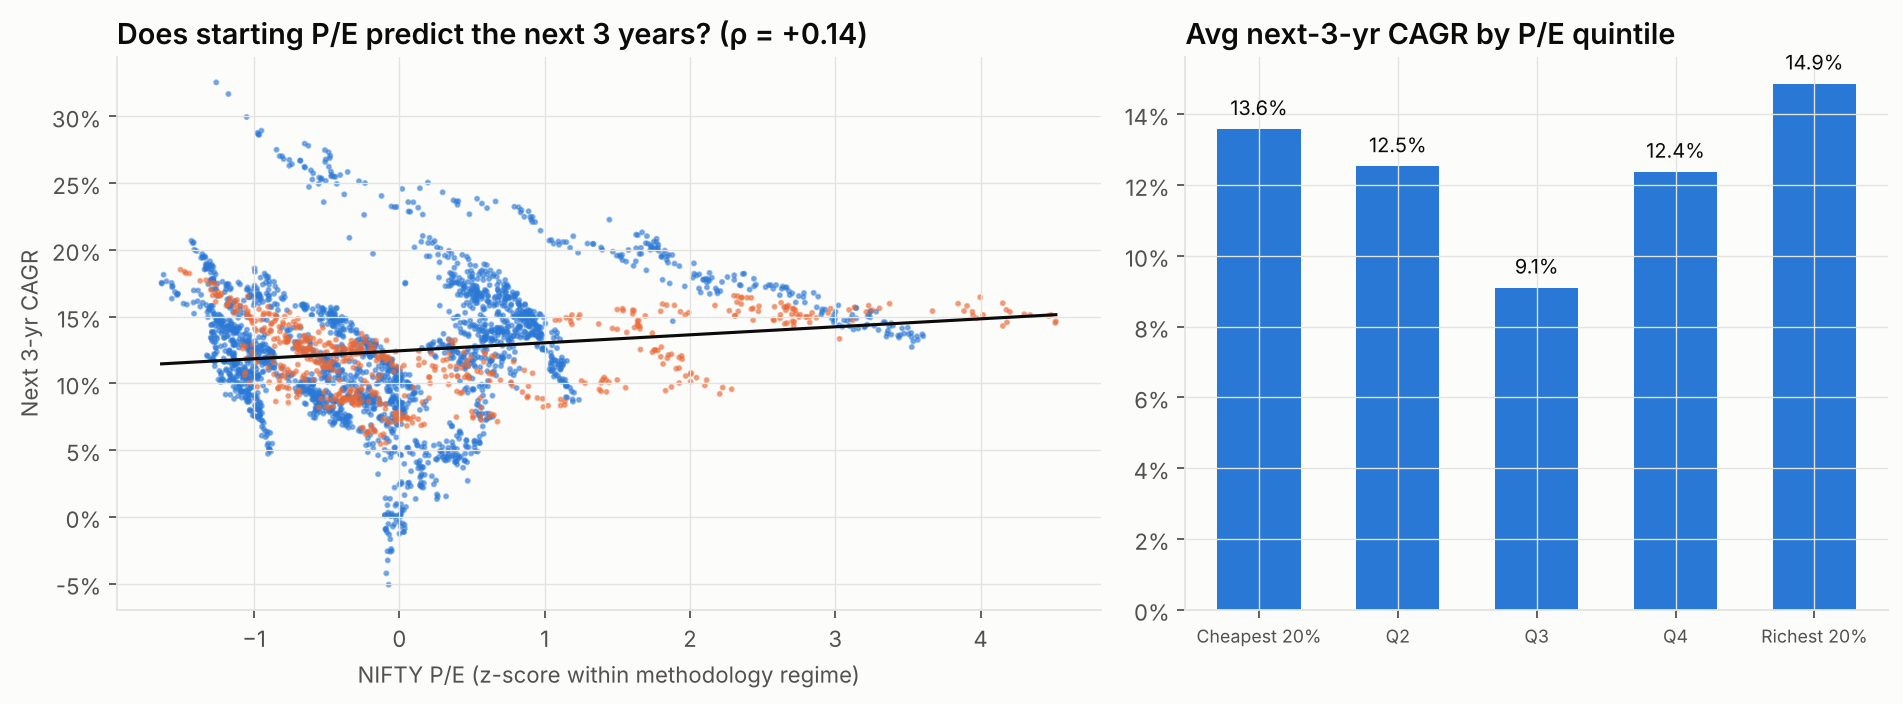

PosixPath('/home/claude/nse-quant-lab/reports/figures/01_valuation.png')

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
c = np.where(val.index < "2021-04-01", PALETTE[0], PALETTE[1])
axes[0].scatter(val["pe_z"], val["fwd3y"], s=3, c=c, alpha=0.5)
xx = np.linspace(X.min(), X.max(), 50)
axes[0].plot(xx, intercept + slope * xx, color="#0b0b0b", lw=1.4)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_xlabel("NIFTY P/E (z-score within methodology regime)"); axes[0].set_ylabel("Next 3-yr CAGR")
axes[0].set_title(f"Does starting P/E predict the next 3 years? (ρ = {rcorr:+.2f})")
axes[1].bar(bucket_tab.index.astype(str), bucket_tab["mean"], color=PALETTE[0], width=0.6)
for i, v in enumerate(bucket_tab["mean"]):
    axes[1].text(i, v + 0.004, f"{v:.1%}", ha="center", fontsize=9, color="#0b0b0b")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Avg next-3-yr CAGR by P/E quintile"); axes[1].tick_params(axis="x", labelsize=8)
save(fig, "01_valuation")

**Result: in 2012-2026, starting P/E did *not* predict 3-year NIFTY returns** (ρ ≈ +0.14, overlap-
adjusted t ≈ 0.3). The textbook "buy cheap" effect (Shiller CAPE in the US) needs decades of data and
full cycles; India's sample is short, earnings growth was lumpy (2014-19 earnings recession inflated
P/E without a return penalty), and the 2021 methodology break halves the usable history.

This is a deliberately reported **null result**: a good analyst says "the data doesn't support it"
rather than forcing the narrative. Note also that the current NIFTY P/E sits near the **bottom** of
its post-2021 range — useful context, not a trading signal.

In [14]:
data.save_results("01_market_risk", {
    "distribution": dist, "garch": garch,
    "var_backtest": var_bt.reset_index().to_dict(orient="records"),
    "drawdowns": dd_tab.assign(peak=dd_tab.peak.astype(str), trough=dd_tab.trough.astype(str),
                               recovered=dd_tab.recovered.astype(str)).to_dict(orient="records"),
    "valuation": {k: (v if not isinstance(v, dict) else {str(a): b for a, b in v.items()}) for k, v in valuation.items()},
})
print("saved")

saved
